# WMS pilotu toplama süresini düşürdü mü?

WMS ekranı 12 pilot depoda değişiyor. 12 kıyas deposu eski ekranı kullanmaya devam ediyor. Her depoda 8 önceki ve 8 sonraki haftanın toplama süresi var. Pilot depolar farklı seviyede başlayabilir ve önceden daha hızlı iyileşiyor olabilir.

Karar: Süre düşüşü pilot etkisiyle uyumlu mu? Kıyas tasarımını güçlendirmek için hangi kanıt gerekir?

Veriler sentetiktir. Her senaryo sabit tohumla aynı veriyi yeniden oluşturur. CSV dosyaları örnek çıktıdır. Bir CSV’yi değiştirmen bu defterin verisini otomatik değiştirmez.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import expit
import matplotlib.pyplot as plt

BLUE, ORANGE, GREEN, GRAY = '#2457ad', '#ac452c', '#197254', '#64748b'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.alpha': .19})

def table(frame, title):
    return dict(title=title, columns=frame.columns.tolist(),
                rows=frame.astype(object).where(frame.notna(), None).values.tolist())

def rollout(scenario='default'):
    rng=np.random.default_rng(72104)
    weeks=np.arange(-8,8)
    change=np.r_[np.ones(12,dtype=bool),np.zeros(12,dtype=bool)]
    site_base=rng.normal(13,1.15,24)+1.7*change
    stable_site_slope=rng.normal(0,.035,24)
    common=.12*weeks+.25*np.sin(weeks)
    noise=rng.normal(0,.65,(24,16))
    baseline=site_base[:,None]+common+stable_site_slope[:,None]*weeks+noise
    if scenario=='pretrend':
        baseline+=change[:,None]*(-.22*weeks)
    effect=-1.45 if scenario=='default' else 0.
    outcome=baseline+effect*change[:,None]*(weeks>=0)
    raw=pd.DataFrame({'Depo':np.repeat(np.arange(1,25),16),'Hafta':np.tile(weeks,24),
                      'Pilot':np.repeat(change,16),'Toplama süresi · dk':outcome.ravel()})
    delta=outcome[:,8:].mean(axis=1)-outcome[:,:8].mean(axis=1)
    a,b=delta[change],delta[~change]
    d=a.mean()-b.mean()
    va,vb=a.var(ddof=1)/len(a),b.var(ddof=1)/len(b)
    se=np.sqrt(va+vb)
    df=(va+vb)**2/(va**2/(len(a)-1)+vb**2/(len(b)-1))
    bounds=stats.t.interval(.95,df,loc=d,scale=se)
    pre=outcome[:,4:8].mean(axis=1)-outcome[:,:4].mean(axis=1)
    placebo=pre[change].mean()-pre[~change].mean()
    fig,ax=plt.subplots(figsize=(8.8,4.3),layout='constrained')
    ax.plot(weeks,outcome[change].mean(axis=0),'o-',color=BLUE,label='Pilot depolar')
    ax.plot(weeks,outcome[~change].mean(axis=0),'s-',color=ORANGE,label='Kıyas depoları')
    ax.axvline(-.5,color=GRAY,ls='--')
    ax.annotate('WMS pilot başlangıcı',(0,outcome[change,8].mean()),xytext=(12,23),textcoords='offset points',fontsize=9)
    ax.set(xlabel='Başlangıca göre hafta',ylabel='Depo ortalaması · dakika',title='Pilot öncesi eğilimlerin yönünü karşılaştır')
    ax.legend()
    fig2,ax2=plt.subplots(figsize=(8.8,3.5),layout='constrained')
    ax2.errorbar([d],[0],xerr=[[d-bounds[0]],[bounds[1]-d]],fmt='o',color=BLUE,capsize=6,label='Pilot dönemi farkların farkı')
    ax2.scatter([placebo],[1],marker='D',color=ORANGE,label='Pilot öncesi sahte başlangıç')
    ax2.axvline(0,color=GRAY,ls='--')
    ax2.set(yticks=[0,1],yticklabels=['Pilot dönemi','Ön dönem'],xlabel='Pilot değişimi − kıyas değişimi · dakika',
            title='Ön dönem ayrışması nedensel yorumu zayıflatır')
    ax2.legend(loc='lower left',fontsize=8)
    detail=pd.DataFrame([['Pilot',12,outcome[change,:8].mean(),outcome[change,8:].mean(),a.mean()],
                         ['Kıyas',12,outcome[~change,:8].mean(),outcome[~change,8:].mean(),b.mean()]],
                        columns=['Grup','Depo','Önce · dk','Sonra · dk','Değişim · dk'])
    return dict(metrics={'Farkların farkı · dk':d,'Aralık · dk':f'{bounds[0]:+.2f}…{bounds[1]:+.2f}',
                         'Ön dönem sahte etki · dk':placebo,'Bağımsız birim':'24 depo'},
        tables=[table(detail,'Her depo aynı ağırlıkta')],
        figures=[('Dikey çizgi geçişi gösterir. Ön seviyelerin farklı olması tek başına sorun değildir. Karşılaştırılan eğilimdir.',fig),
                 ('Ön dönem göstergesi tek bir tanıdır. Yakın sıfır paralel eğilimi kanıtlamaz.',fig2)],
        frames={'depo_hafta':raw,'depo_degisimleri':pd.DataFrame({'Depo':np.arange(1,25),'Pilot':change,'Sonra − önce · dk':delta})},
        steps=['Pilot ve kıyas depolarını müdahale öncesi koşullara göre tanımla. Hedef her depoya eşit ağırlık veren ortalama değişim.',
               'Her depo için sekiz sonraki haftanın ortalamasından sekiz önceki haftanın ortalamasını çıkar. Pilot ortalama değişiminden kıyas ortalamasını çıkar.',
               'Belirsizliği 384 depo-hafta yerine 24 depo değişimi üzerinden Welch ile hesapla. Ön dönem sahte başlangıcı ve eşzamanlı değişiklikleri ayrıca incele.'],
        decision='Ön eğilimlerde büyük ayrışma görünmüyor. Sonuç pilotla uyumlu bir iyileşme, fakat vardiya/müşteri karması gibi eşzamanlı değişiklikleri saha kayıtlarıyla doğrula.' if scenario=='default' else 'Pilot öncesinde de benzer yönlü fark var. Gözlenen negatif DiD değerini WMS etkisi olarak raporlama. Kıyas grubu ve geçiş takvimini yeniden kur.',
        limit='Atama gözlemsel. Nedensel yorum için koşullu paralel eğilim, müdahale beklentisi ve yayılma olmaması gerekir. Depo bağımsızlığı, ortak bölgesel şoklar ve önceden seçilen pencere ayrıca sorgulanır. Çok zamanlı kademeli geçiş için bu iki dönem özeti yeterli değildir.',
        diagnostics={'did':d,'ci':bounds,'placebo':placebo,'simulated_effect':effect,'sites':24},
        focus=[['Ön dönem','8 hafta','Kıyas eğilimini kontrol et'],['Etki tahmini',f'{d:+.2f} dk','İki değişimin farkı'],['Sahte başlangıç',f'{placebo:+.2f} dk','Geçişten önce benzer fark var mı?']])


def print_result(result):
    for name, value in result['metrics'].items():
        print(f"{name}: {value}")
    print()
    for t in result['tables']:
        print(t['title'])
        print(pd.DataFrame(t['rows'], columns=t['columns']).to_string(index=False))
        print()
    print('Karar:', result['decision'])
    print('Koşullar:', result['limit'])


## Ön eğilimler benzer

Pilot depolarda değişim -0.223 dk, kıyas depolarında +1.094 dk. Pilot değişimi eksi kıyas değişimi kaç dakika?


Farkların farkı · dk: -1.3171536380850046
Aralık · dk: -1.59…-1.05
Ön dönem sahte etki · dk: 0.06865211107905339
Bağımsız birim: 24 depo

Her depo aynı ağırlıkta
 Grup  Depo  Önce · dk  Sonra · dk  Değişim · dk
Pilot    12  13.842009   13.619289     -0.222720
Kıyas    12  12.105243   13.199676      1.094434

Karar: Ön eğilimlerde büyük ayrışma görünmüyor. Sonuç pilotla uyumlu bir iyileşme, fakat vardiya/müşteri karması gibi eşzamanlı değişiklikleri saha kayıtlarıyla doğrula.
Koşullar: Atama gözlemsel. Nedensel yorum için koşullu paralel eğilim, müdahale beklentisi ve yayılma olmaması gerekir. Depo bağımsızlığı, ortak bölgesel şoklar ve önceden seçilen pencere ayrıca sorgulanır. Çok zamanlı kademeli geçiş için bu iki dönem özeti yeterli değildir.


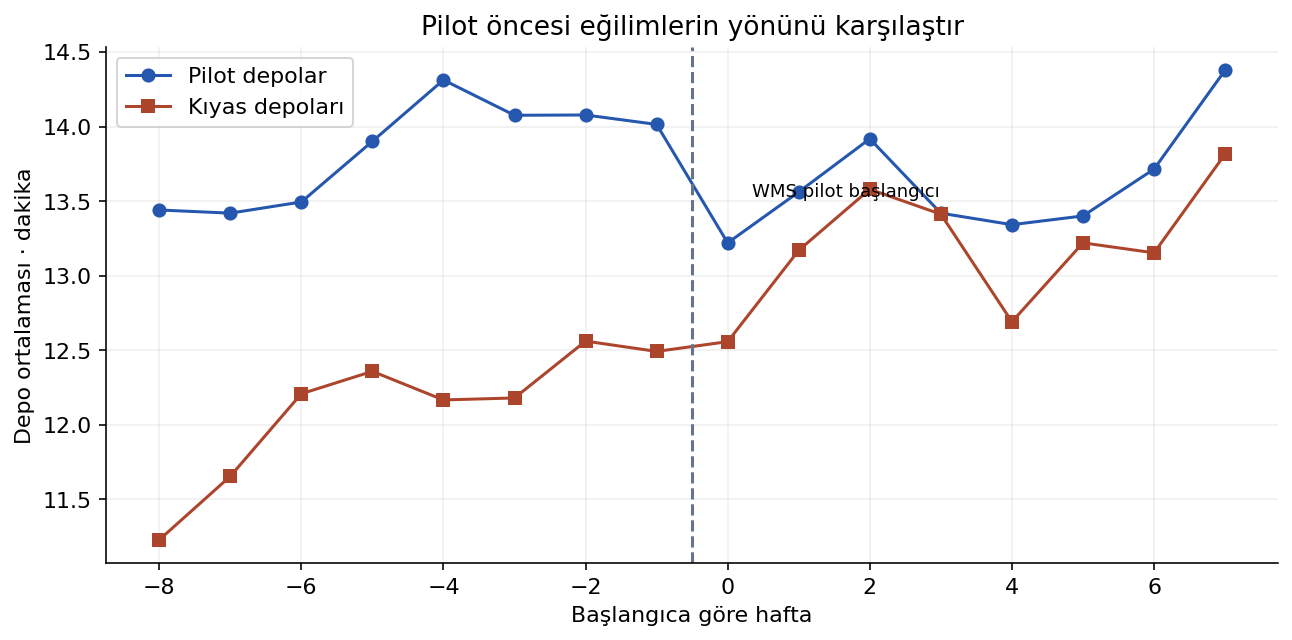

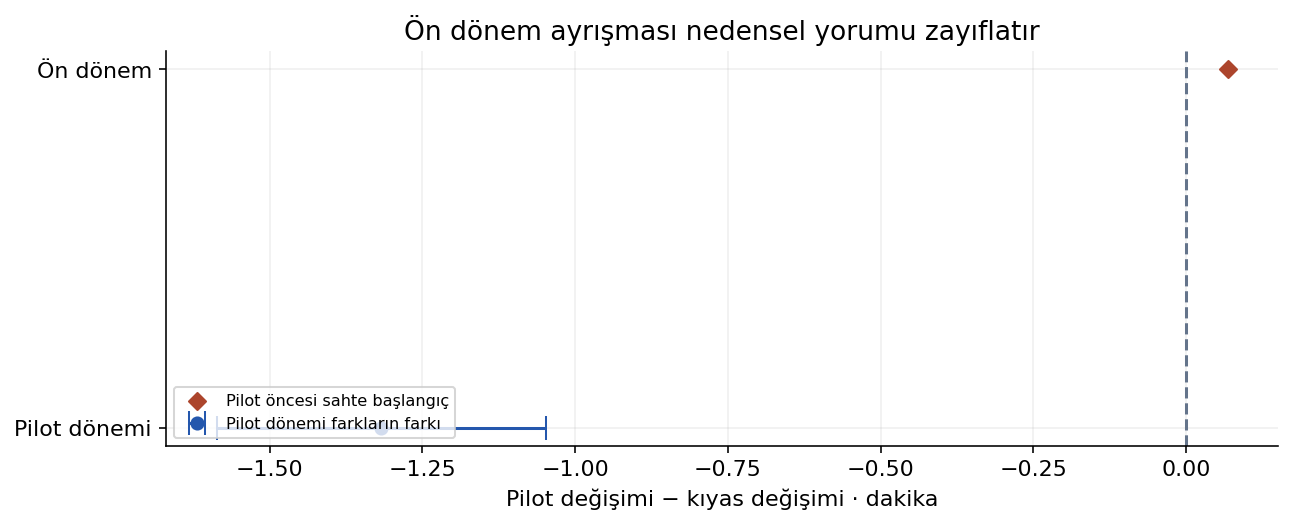

In [2]:
result = rollout('default')
print_result(result)
plt.show()


## Pilot depolar önceden iyileşiyor

Pilot depolarda değişim -0.533 dk, kıyas depolarında +1.094 dk. Pilot değişimi eksi kıyas değişimi kaç dakika?


Farkların farkı · dk: -1.6271536380850053
Aralık · dk: -1.90…-1.36
Ön dönem sahte etki · dk: -0.8113478889209464
Bağımsız birim: 24 depo

Her depo aynı ağırlıkta
 Grup  Depo  Önce · dk  Sonra · dk  Değişim · dk
Pilot    12  14.832009   14.299289     -0.532720
Kıyas    12  12.105243   13.199676      1.094434

Karar: Pilot öncesinde de benzer yönlü fark var. Gözlenen negatif DiD değerini WMS etkisi olarak raporlama. Kıyas grubu ve geçiş takvimini yeniden kur.
Koşullar: Atama gözlemsel. Nedensel yorum için koşullu paralel eğilim, müdahale beklentisi ve yayılma olmaması gerekir. Depo bağımsızlığı, ortak bölgesel şoklar ve önceden seçilen pencere ayrıca sorgulanır. Çok zamanlı kademeli geçiş için bu iki dönem özeti yeterli değildir.


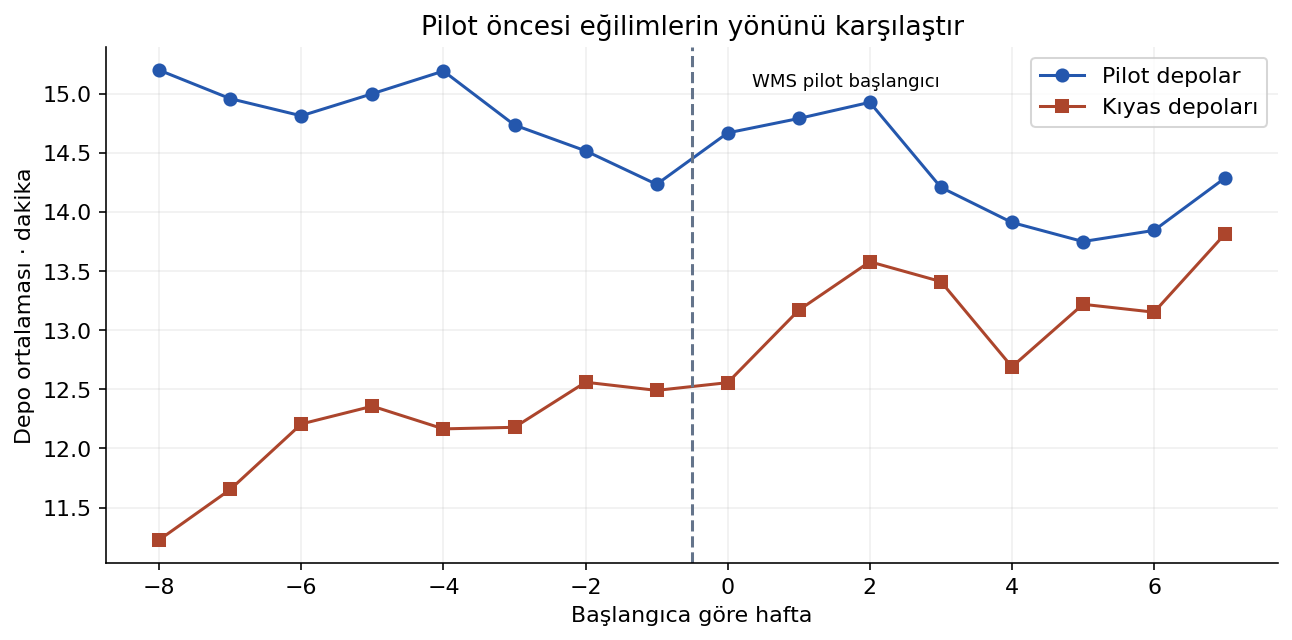

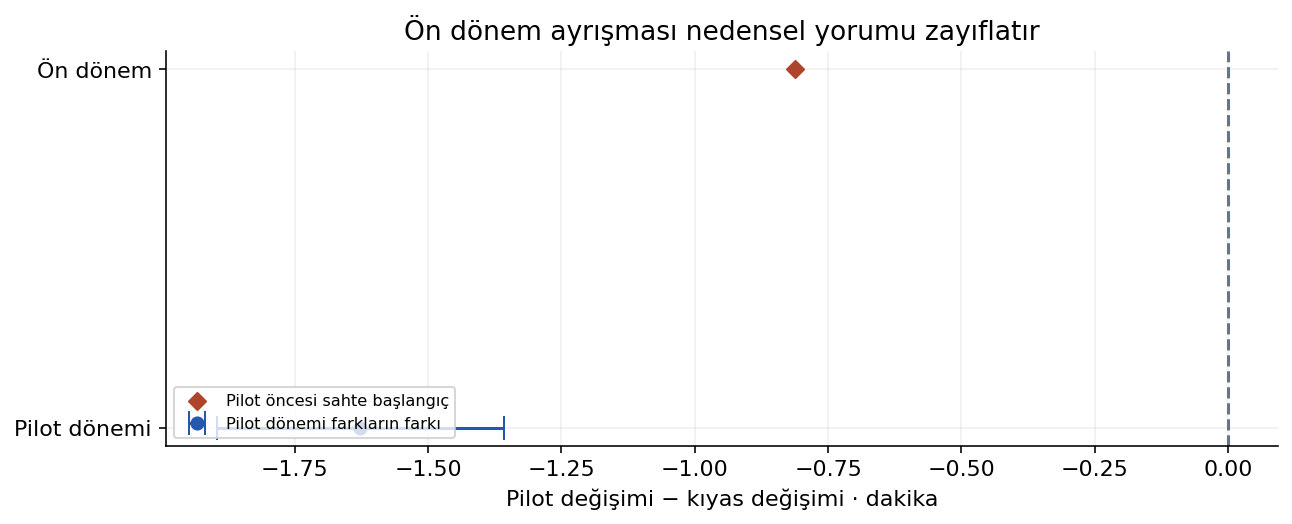

In [3]:
result = rollout('pretrend')
print_result(result)
plt.show()


## Karar notu

Her iki senaryoda da DiD negatiftir. Hangi durumda neden nedensel yorumu sınırlandırırsın? Bir sonraki saha kontrolünü belirt.

- Pilot değişimi − kıyas değişimi yönünü koru.
- Ön dönem ayrışmasını ve depo düzeyinde birimi açıkla.
- Karma, vardiya veya eşzamanlı proje değişimini araştır.